 Imports

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cv2
import os
from pathlib import Path
import pandas as pd
from collections import Counter
import seaborn as sns
import warnings
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
import random
import shutil
warnings.filterwarnings('ignore')


Chargement du dataset

In [7]:
# Chemin vers ton dataset PlantVillage
DATASET_PATH = "C:\\Users\\MSI\\OneDrive\\Desktop\\IGL4\\SEM2\\IngImage\\Project2\\PlantVillage"

# Lister toutes les classes
classes = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d))])
print(f"Nombre de classes : {len(classes)}\n")
print("Classes disponibles (avec index):")
for i, cls in enumerate(classes):
    cls_path = Path(DATASET_PATH) / cls
    if cls_path.is_dir():
        n_images = len(list(cls_path.glob('*.jpg')) + list(cls_path.glob('*.JPG')) + list(cls_path.glob('*.png')))
        print(f"  [{i:2d}] {cls:<60} ({n_images} images)")


Nombre de classes : 15

Classes disponibles (avec index):
  [ 0] Pepper__bell___Bacterial_spot                                (1994 images)
  [ 1] Pepper__bell___healthy                                       (2955 images)
  [ 2] Potato___Early_blight                                        (2000 images)
  [ 3] Potato___Late_blight                                         (2000 images)
  [ 4] Potato___healthy                                             (304 images)
  [ 5] Tomato_Bacterial_spot                                        (4254 images)
  [ 6] Tomato_Early_blight                                          (2000 images)
  [ 7] Tomato_Late_blight                                           (3816 images)
  [ 8] Tomato_Leaf_Mold                                             (1904 images)
  [ 9] Tomato_Septoria_leaf_spot                                    (3542 images)
  [10] Tomato_Spider_mites_Two_spotted_spider_mite                  (3352 images)
  [11] Tomato__Target_Spot               

Analyse Exploratoire du Dataset (EDA)

============= Structure du dataset ===========
Total images     : 41273
Nombre de classes: 15
Plantes uniques  : 10
Images saines    : 6441 (15.6%)
Images malades   : 34832 (84.4%)

============= Distribution des classes ===========


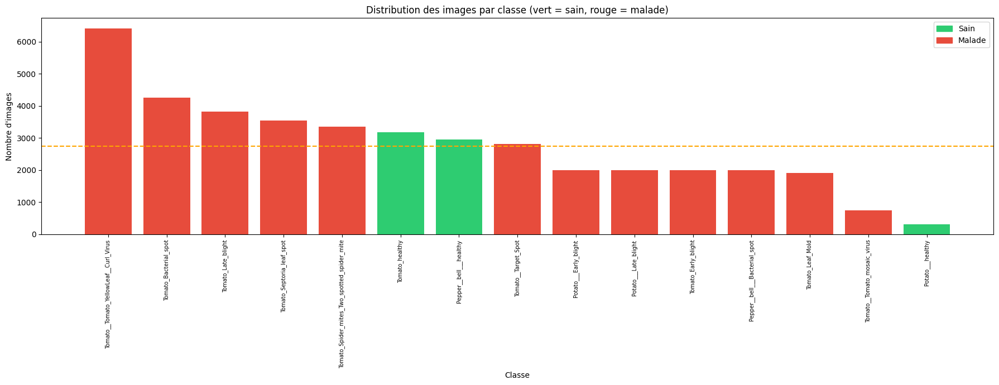


Classe avec le plus d'images  : Tomato__Tomato_YellowLeaf__Curl_Virus (6416)
Classe avec le moins d'images : Potato___healthy (304)
Écart-type : 1489  → déséquilibre des classes important

============= Distribution par plante ===========


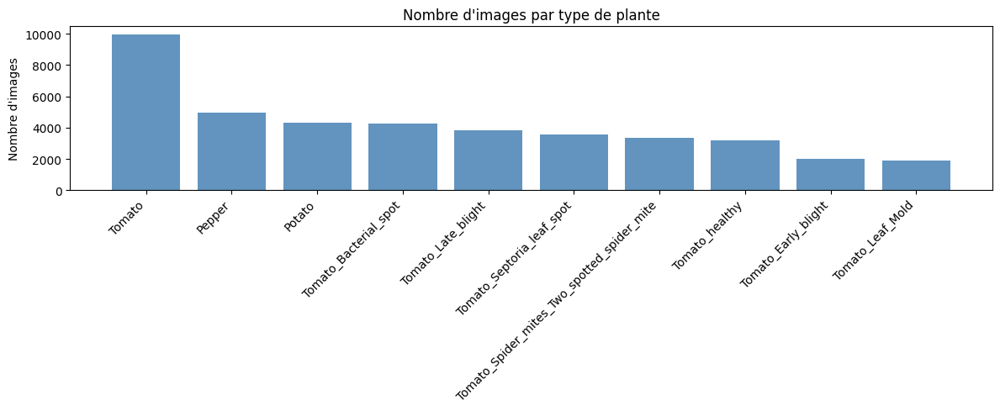


============= Ratio sain vs malade global et par plante ===========


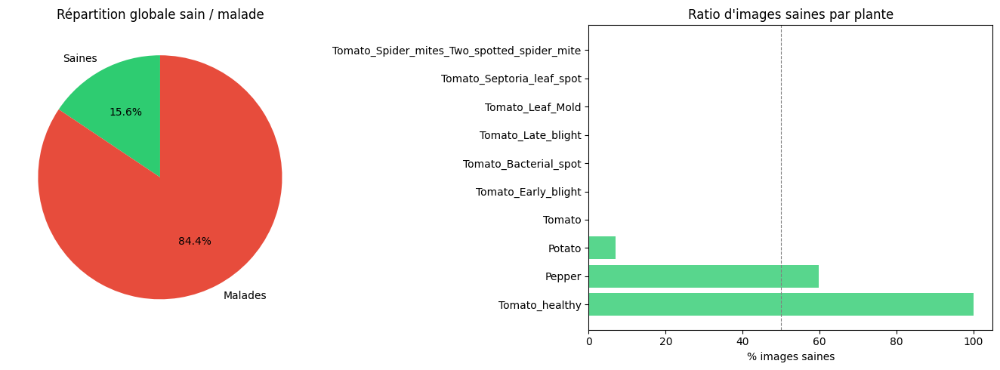


============= Visualisation d'exemples par classe ===========


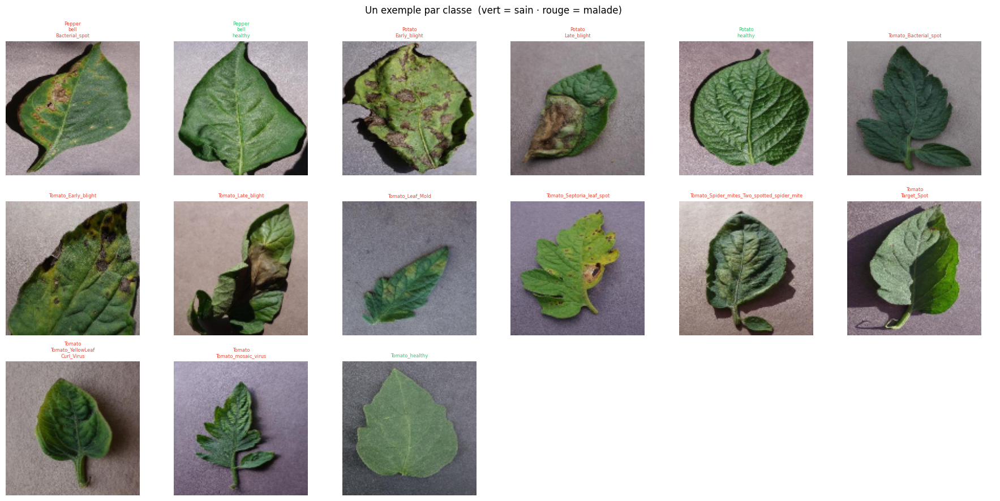


============= Analyse colorimétrique moyenne par classe ===========


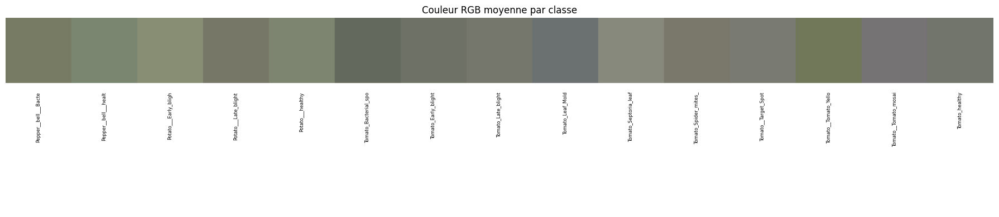

In [8]:
#0.1 - Structure du dataset
# Construire un dataframe avec toutes les infos
print("============= Structure du dataset ===========")
records = []
for cls in sorted(os.listdir(DATASET_PATH)):
    cls_path = Path(DATASET_PATH) / cls
    if not cls_path.is_dir():
        continue
    images = list(cls_path.glob("*.jpg")) + list(cls_path.glob("*.JPG")) + list(cls_path.glob("*.png"))
    # Extraire plante et état depuis le nom de classe (ex: "Tomato__Early_blight")
    parts = cls.split("__")
    plant  = parts[0] if len(parts) > 1 else cls
    status = parts[1] if len(parts) > 1 else "Unknown"
    healthy = "healthy" in cls.lower()
    for img_path in images:
        records.append({
            "class":   cls,
            "plant":   plant,
            "status":  status,
            "healthy": healthy,
            "path":    str(img_path)
        })

df = pd.DataFrame(records)
print(f"Total images     : {len(df)}")
print(f"Nombre de classes: {df['class'].nunique()}")
print(f"Plantes uniques  : {df['plant'].nunique()}")
print(f"Images saines    : {df['healthy'].sum()} ({df['healthy'].mean()*100:.1f}%)")
print(f"Images malades   : {(~df['healthy']).sum()} ({(~df['healthy']).mean()*100:.1f}%)")

#0.2 - Distribution des classes 
print("\n============= Distribution des classes ===========")
class_counts = df.groupby('class').size().sort_values(ascending=False)

plt.figure(figsize=(18, 7))
bars = plt.bar(range(len(class_counts)), class_counts.values,
               color=['#2ecc71' if 'healthy' in c.lower() else '#e74c3c'
                      for c in class_counts.index])
plt.xticks(range(len(class_counts)), class_counts.index, rotation=90, fontsize=7)
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.title("Distribution des images par classe (vert = sain, rouge = malade)")
plt.axhline(class_counts.mean(), color='orange', linestyle='--',
            label=f'Moyenne : {class_counts.mean():.0f}')
healthy_patch = mpatches.Patch(color='#2ecc71', label='Sain')
diseased_patch = mpatches.Patch(color='#e74c3c', label='Malade')
plt.legend(handles=[healthy_patch, diseased_patch])
plt.tight_layout()
plt.show()

print(f"\nClasse avec le plus d'images  : {class_counts.idxmax()} ({class_counts.max()})")
print(f"Classe avec le moins d'images : {class_counts.idxmin()} ({class_counts.min()})")
print(f"Écart-type : {class_counts.std():.0f}  → déséquilibre des classes important")

#0.3 - Distribution par plante
print("\n============= Distribution par plante ===========")
plant_counts = df.groupby('plant').size().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(plant_counts.index, plant_counts.values, color='steelblue', alpha=0.85)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Nombre d'images")
plt.title("Nombre d'images par type de plante")
plt.tight_layout()
plt.show()


#0.4 - Ratio sain vs malade global et par plante
print("\n============= Ratio sain vs malade global et par plante ===========")
# Global
labels = ['Saines', 'Malades']
sizes  = [df['healthy'].sum(), (~df['healthy']).sum()]
colors = ['#2ecc71', '#e74c3c']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
ax1.set_title("Répartition globale sain / malade")

# Par plante
ratio = df.groupby('plant')['healthy'].mean().sort_values(ascending=False)
ax2.barh(ratio.index, ratio.values * 100, color='#2ecc71', alpha=0.8)
ax2.axvline(50, color='gray', linestyle='--', linewidth=0.8)
ax2.set_xlabel("% images saines")
ax2.set_title("Ratio d'images saines par plante")
plt.tight_layout()
plt.show()


#0.5 - Visualisation d'exemples par classe
print("\n============= Visualisation d'exemples par classe ===========")
# Afficher 1 image par classe (grille 6x7 pour 38 classes)
n_cols = 6
n_rows = -(-len(classes) // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))
axes = axes.flatten()

for i, cls in enumerate(sorted(df['class'].unique())):
    row = df[df['class'] == cls].iloc[0]
    img = cv2.imread(row['path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (128, 128))
    axes[i].imshow(img)
    label = cls.replace("___", "\n").replace("__", "\n")
    color = '#2ecc71' if row['healthy'] else '#e74c3c'
    axes[i].set_title(label, fontsize=6, color=color)
    axes[i].axis('off')

# Cacher les axes vides
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Un exemple par classe  (vert = sain · rouge = malade)", fontsize=12)
plt.tight_layout()
plt.show()

#0.6 - Analyse colorimétrique moyenne par classe
print("\n============= Analyse colorimétrique moyenne par classe ===========")
# Couleur moyenne RGB par classe (échantillon de 50 imgs/classe)
mean_colors = {}
for cls in df['class'].unique():
    paths = df[df['class'] == cls]['path'].sample(min(50, len(df[df['class'] == cls])),
                                                    random_state=42).tolist()
    means = []
    for p in paths:
        img = cv2.imread(p)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (64, 64))
            means.append(img.mean(axis=(0, 1)))
    if means:
        mean_colors[cls] = np.mean(means, axis=0) / 255.0

# Afficher comme palette de couleurs
fig, ax = plt.subplots(figsize=(18, 4))
for i, (cls, color) in enumerate(sorted(mean_colors.items())):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=color))
    ax.text(i + 0.5, -0.15, cls[:20], rotation=90, ha='center', va='top', fontsize=6)

ax.set_xlim(0, len(mean_colors))
ax.set_ylim(-2, 1)
ax.axis('off')
ax.set_title("Couleur RGB moyenne par classe")
plt.tight_layout()
plt.show()


Prétraitement des images


============= Configuration ===========
  Tomato_Bacterial_spot                                        → 600 images
  Tomato_Early_blight                                          → 600 images
  Tomato_Late_blight                                           → 600 images
  Tomato_Leaf_Mold                                             → 600 images
  Tomato_Septoria_leaf_spot                                    → 600 images
  Tomato_Spider_mites_Two_spotted_spider_mite                  → 600 images
  Tomato__Target_Spot                                          → 600 images
  Tomato__Tomato_YellowLeaf__Curl_Virus                        → 600 images
  Tomato__Tomato_mosaic_virus                                  → 600 images
  Tomato_healthy                                               → 600 images

Total : 15053 images | 10 classes
class
Tomato_Bacterial_spot                          1993
Tomato_Early_blight                             999
Tomato_Late_blight                             1809
To

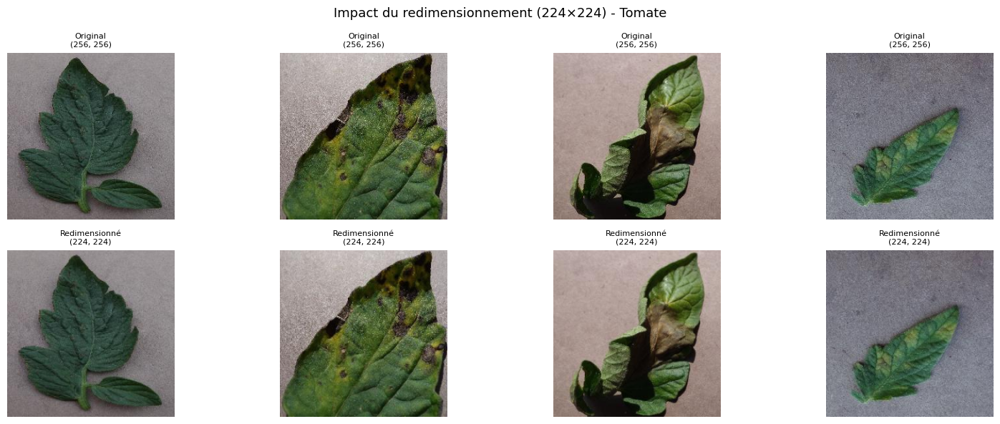

Utilité : uniformiser toutes les images → vecteurs de taille identique pour le ML

============= Conversion des espaces colorimétriques ===========


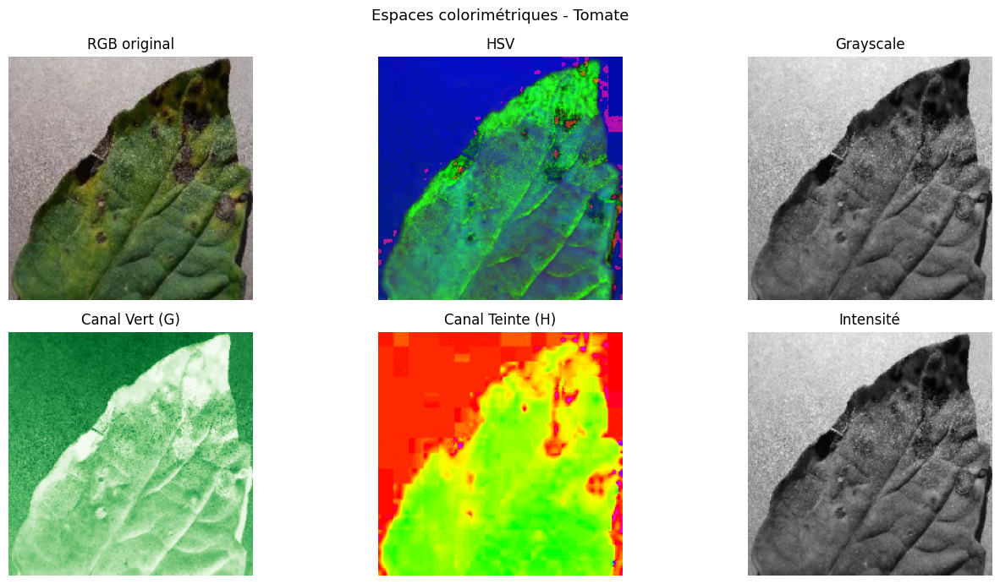


Utilité :
  HSV  → sépare teinte (H) et luminosité (V) → robuste aux variations d'éclairage
          idéal pour détecter les taches jaunes/brunes des maladies de la tomate
  Gray → nécessaire pour le calcul GLCM (texture) à l'étape 3


============= Filtrage du bruit ===========


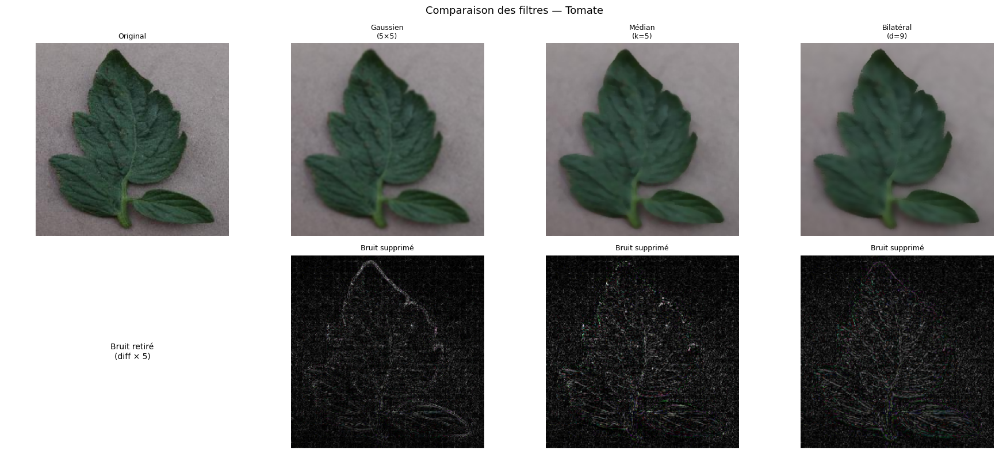


Comparaison :
  Gaussien  → rapide, lisse uniformément, efface un peu les contours
  Médian    → bon contre le bruit sel/poivre
  Bilatéral → préserve les contours des lésions tout en lissant
→ Choix retenu : GaussianBlur (standard, rapide, suffisant pour les features)


============= Analyse des histogrammes ===========


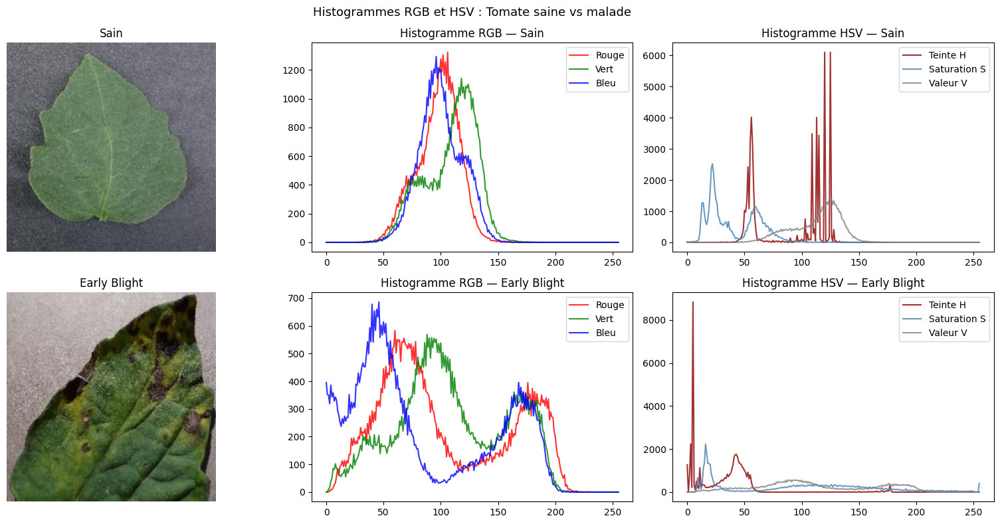


Lecture :
  Saine  → pic dominant canal VERT (RGB) et teinte verte (H~60 en HSV)
  Malade → canaux ROUGE/BLEU plus présents → taches brunes/jaunes visibles
  → Confirme que la couleur est un feature discriminant fort


============= Fonction preprocess_image finale ===========


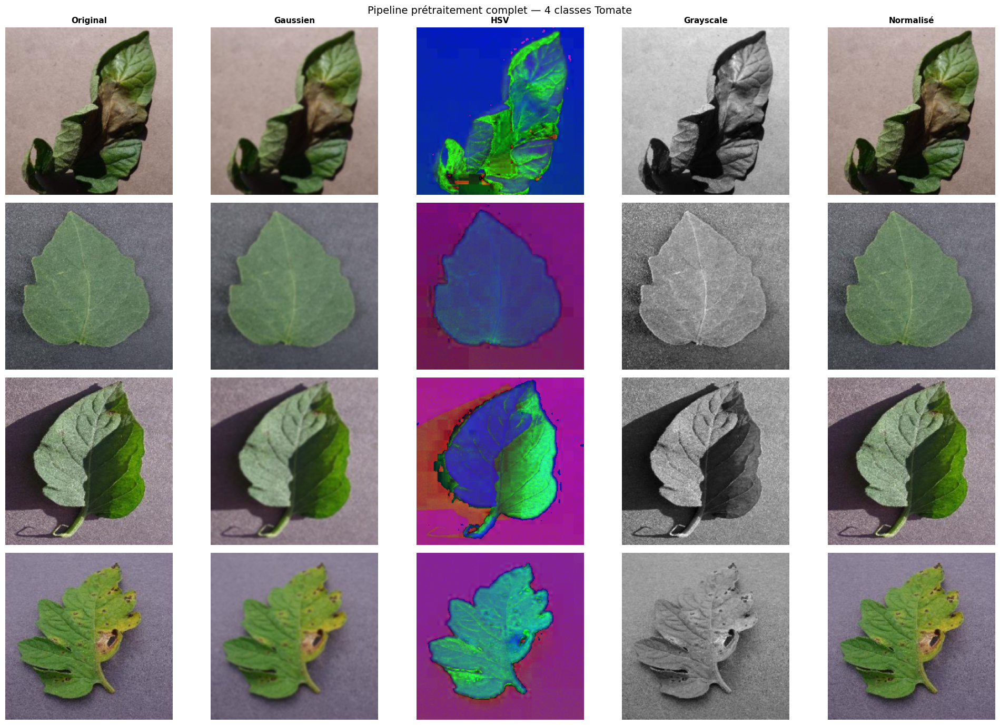

RGB  : min=0  max=171  dtype=uint8
Norm : min=0.00 max=0.67 dtype=float64

============= Égalisation de contraste (CLAHE) ===========


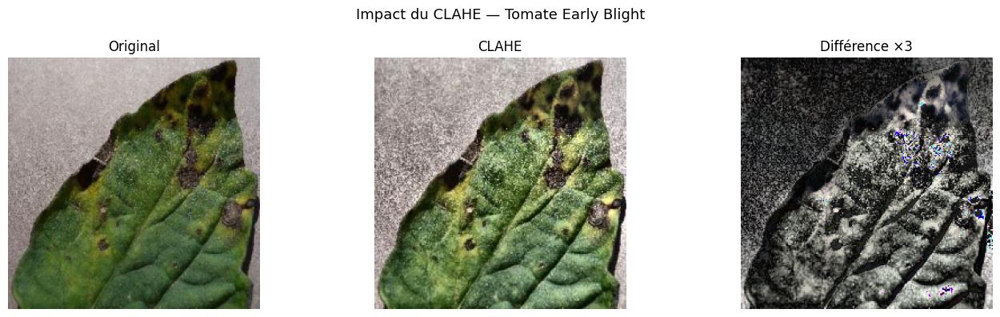

In [9]:
#0 - Configuration 
print("\n============= Configuration ===========")
IMG_SIZE = (224, 224)

SELECTED_CLASSES = [
    'Tomato_Bacterial_spot',
    'Tomato_Early_blight',
    'Tomato_Late_blight',
    'Tomato_Leaf_Mold',
    'Tomato_Septoria_leaf_spot',
    'Tomato_Spider_mites_Two_spotted_spider_mite',
    'Tomato__Target_Spot',
    'Tomato__Tomato_YellowLeaf__Curl_Virus',
    'Tomato__Tomato_mosaic_virus',
    'Tomato_healthy',
]
MAX_IMAGES_PER_CLASS = 600

# Organiser le sous-dataset Tomate
WORK_DIR = Path('./content/tomato_10classes')
WORK_DIR.mkdir(parents=True, exist_ok=True)
#garder en mémoire combien d'images on a copié par classe
class_info = {}
for cls in SELECTED_CLASSES:
    src = Path(DATASET_PATH) / cls #exp : src = Path("/plantvillage") / "Tomato_Early_blight"
    dst = WORK_DIR / cls #exp : dst = ./content/tomato_10classes/Tomato_Early_blight
    dst.mkdir(exist_ok=True) #si le dossier existe deja ne fait pas erreur
    #On cherche toutes les images dans le dossier source.
    images = list(src.glob('*.jpg')) + list(src.glob('*.JPG')) + list(src.glob('*.png'))
    #On prend un échantillon de 600 images par classe
    images = random.sample(images, min(MAX_IMAGES_PER_CLASS, len(images)))
    #On copie les images dans le dossier destination
    for img_path in images:
        shutil.copy(img_path, dst / img_path.name)
    class_info[cls] = len(images)
    print(f"  {cls:<60} → {len(images)} images")

# Reconstruire le dataframe sur les 10 classes uniquement
records = []
for cls in SELECTED_CLASSES:
    for img_path in (WORK_DIR / cls).glob('*.*'):
        records.append({
            'class':   cls,
            'plant':   'Tomato',
            'status':  cls.replace('Tomato_', '').replace('Tomato__', ''),
            'healthy': 'healthy' in cls.lower(),
            'path':    str(img_path)
        })
#resultat : Pour chaque image, créer un dictionnaire :
# {
#   'class'  : nom de la classe          → label pour le ML
#   'plant'  : 'Tomato'                  → info générale
#   'status' : nom de la maladie seul    → info lisible
#   'healthy': True / False              → analyse binaire
#   'path'   : chemin de l'image         → pour charger l'image
# }
df_tomato = pd.DataFrame(records)
print(f"\nTotal : {len(df_tomato)} images | {df_tomato['class'].nunique()} classes")
print(df_tomato.groupby('class').size())

#1 - Redimensionnement
print("\n============= Redimensionnement ===========")
# **Description :** Toutes les images sont redimensionnées à 224×224 pixels
# via l'interpolation `INTER_AREA`.
# **Utilité :** Uniformiser la taille des entrées du modèle ML et DL.
# Sans cette étape, les vecteurs de features auraient des dimensions différentes.
# *Visualisation ci-dessous : image originale vs redimensionnée.*
"""L'interpolation c'est la méthode mathématique qui décide comment calculer la valeur des nouveaux pixels à partir des anciens."""
def resize_image(img, size=IMG_SIZE):
    """Redimensionne à 224×224. INTER_AREA évite les artefacts."""
    return cv2.resize(img, size, interpolation=cv2.INTER_AREA)

# Visualisation avant / après sur 4 classes Tomate
sample_paths = {cls: df_tomato[df_tomato['class'] == cls].iloc[0]['path']
                for cls in list(df_tomato['class'].unique())[:4]}

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for col, (cls, path) in enumerate(sample_paths.items()):
    img   = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    img_r = resize_image(img)
    axes[0, col].imshow(img)
    axes[0, col].set_title(f"Original\n{img.shape[:2]}", fontsize=8)
    axes[0, col].axis('off') #désactive complètement l’affichage des axes
    axes[1, col].imshow(img_r)
    axes[1, col].set_title(f"Redimensionné\n{img_r.shape[:2]}", fontsize=8)
    axes[1, col].axis('off')

axes[0, 0].set_ylabel("Avant", fontsize=10, fontweight='bold')
axes[1, 0].set_ylabel("Après", fontsize=10, fontweight='bold')
plt.suptitle("Impact du redimensionnement (224×224) - Tomate", fontsize=13)
plt.tight_layout()
plt.savefig('resize.png', dpi=150, bbox_inches='tight')
plt.show()
print("Utilité : uniformiser toutes les images → vecteurs de taille identique pour le ML")

#2 - Conversion des espaces colorimétriques
print("\n============= Conversion des espaces colorimétriques ===========")
# **Description :** Chaque image RGB est convertie en HSV et en Grayscale.(H (Hue) → couleur (teinte), S (Saturation) → intensité de la couleur, V (Value) → luminosité)
# **Utilité :** L'espace HSV sépare la teinte (H) de la luminosité (V),
# rendant la détection des taches colorées robuste aux variations d'éclairage.
# Le Grayscale est nécessaire pour le calcul de texture GLCM (étape 3).
# *Visualisation ci-dessous : RGB original → HSV → Grayscale avec canaux séparés.*
def convert_colorspaces(img_rgb):
    """RGB → HSV et Grayscale."""
    hsv  = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return hsv, gray

img = resize_image(cv2.cvtColor(cv2.imread(list(sample_paths.values())[1]),
                                cv2.COLOR_BGR2RGB))
hsv, gray = convert_colorspaces(img)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes[0,0].imshow(img);               axes[0,0].set_title("RGB original")
axes[0,1].imshow(hsv);               axes[0,1].set_title("HSV")
axes[0,2].imshow(gray, cmap='gray'); axes[0,2].set_title("Grayscale")
axes[1,0].imshow(img[:,:,1], cmap='Greens'); axes[1,0].set_title("Canal Vert (G)")
axes[1,1].imshow(hsv[:,:,0], cmap='hsv');    axes[1,1].set_title("Canal Teinte (H)")
axes[1,2].imshow(gray,       cmap='gray');   axes[1,2].set_title("Intensité")

for ax in axes.flatten(): ax.axis('off')
plt.suptitle("Espaces colorimétriques - Tomate", fontsize=13)
plt.tight_layout()
plt.savefig('colorspaces.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
Utilité :
  HSV  → sépare teinte (H) et luminosité (V) → robuste aux variations d'éclairage
          idéal pour détecter les taches jaunes/brunes des maladies de la tomate
  Gray → nécessaire pour le calcul GLCM (texture) à l'étape 3
""")


#3 — Filtrage du bruit
print("\n============= Filtrage du bruit ===========")
# **Description :** Trois filtres sont comparés : Gaussien (5×5),
# Médian (k=5) et Bilatéral (d=9). Le filtre Gaussien est retenu.
# **Utilité :** Réduire le bruit de capture tout en préservant
# les contours des lésions, pour améliorer la qualité des features extraites.
# *Visualisation ci-dessous : image originale vs filtrée + bruit retiré (×5).*
def apply_filters(img):
    """Compare 3 filtres de débruitage."""
    """Remarques : 
    *Si img est une image couleur (RGB), le filtre est appliqué sur chaque canal.
    *(5,5) : pour chaque pixel, le filtre regarde un bloc de 5 x 5 voisins.
    *sigmaColor : plus il est élevé, plus les couleurs différentes sont mélangées
    *sigmaSpace : plus il est élevé, plus les pixels éloignés influencent le résultat
    *medianBlur(5) : 5 est la taille du voisinage considéré pour le calcul de la médiane
     (doit être impair pour avoir un pixel central)
    """
    gaussian  = cv2.GaussianBlur(img, (5, 5), 0)
    median    = cv2.medianBlur(img, 5)
    bilateral = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)
    return gaussian, median, bilateral
#Attention: OpenCV charge par défaut en BGR (pas RGB).

img = resize_image(cv2.cvtColor(cv2.imread(list(sample_paths.values())[0]),
                                cv2.COLOR_BGR2RGB))
gauss, med, bilat = apply_filters(img)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
titres = ["Original", "Gaussien\n(5×5)", "Médian\n(k=5)", "Bilatéral\n(d=9)"]
images = [img, gauss, med, bilat]

for ax, image, titre in zip(axes[0], images, titres):
    ax.imshow(image); ax.set_title(titre, fontsize=9); ax.axis('off')

axes[1,0].axis('off')
axes[1,0].text(0.5, 0.5, "Bruit retiré\n(diff × 5)",
               ha='center', va='center', fontsize=10,
               transform=axes[1,0].transAxes)
for ax, image in zip(axes[1,1:], [gauss, med, bilat]):
    diff = cv2.absdiff(img, image)
    ax.imshow(np.clip(diff * 5, 0, 255).astype(np.uint8))
    ax.set_title("Bruit supprimé", fontsize=9); ax.axis('off')

plt.suptitle("Comparaison des filtres — Tomate", fontsize=13)
plt.tight_layout()
plt.savefig('filtres.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
Comparaison :
  Gaussien  → rapide, lisse uniformément, efface un peu les contours
  Médian    → bon contre le bruit sel/poivre
  Bilatéral → préserve les contours des lésions tout en lissant
→ Choix retenu : GaussianBlur (standard, rapide, suffisant pour les features)
""")


#4 — Histogrammes RGB et HSV : sain vs malade
print("\n============= Analyse des histogrammes ===========")
# **Description :** Les histogrammes RGB et HSV sont calculés et comparés
# sur une feuille saine et une feuille malade (Early Blight).
# **Utilité :** Vérifier que la distribution des couleurs diffère entre
# classes saines et malades, ce qui valide la couleur comme feature
# discriminante pour l'étape 3.
# *Visualisation ci-dessous : histogrammes RGB et HSV, sain vs malade.*
cls_sain   = 'Tomato_healthy'
cls_malade = 'Tomato_Early_blight'

img_sain   = resize_image(cv2.cvtColor(
    cv2.imread(df_tomato[df_tomato['class']==cls_sain].iloc[0]['path']),
    cv2.COLOR_BGR2RGB))
img_malade = resize_image(cv2.cvtColor(
    cv2.imread(df_tomato[df_tomato['class']==cls_malade].iloc[0]['path']),
    cv2.COLOR_BGR2RGB))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, (img, label) in enumerate([(img_sain,'Sain'),(img_malade,'Early Blight')]):
    axes[row,0].imshow(img); axes[row,0].set_title(label); axes[row,0].axis('off')

    for ch, (color, name) in enumerate(zip(('r','g','b'),('Rouge','Vert','Bleu'))):
        hist = cv2.calcHist([img], [ch], None, [256], [0,256])
        axes[row,1].plot(hist, color=color, label=name, alpha=0.8)
    axes[row,1].set_title(f"Histogramme RGB — {label}")
    axes[row,1].legend()

    hsv_img = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    for ch, (color, name) in enumerate(zip(
        ('darkred','steelblue','gray'),('Teinte H','Saturation S','Valeur V'))):
        hist = cv2.calcHist([hsv_img], [ch], None, [256], [0,256])
        axes[row,2].plot(hist, color=color, label=name, alpha=0.8)
    axes[row,2].set_title(f"Histogramme HSV — {label}")
    axes[row,2].legend()

plt.suptitle("Histogrammes RGB et HSV : Tomate saine vs malade", fontsize=13)
plt.tight_layout()
plt.savefig('histogrammes.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
Lecture :
  Saine  → pic dominant canal VERT (RGB) et teinte verte (H~60 en HSV)
  Malade → canaux ROUGE/BLEU plus présents → taches brunes/jaunes visibles
  → Confirme que la couleur est un feature discriminant fort
""")


#5 — Fonction preprocess_image finale
print("\n============= Fonction preprocess_image finale ===========")
# **Description :** Fonction unique regroupant tous les traitements retenus :
# resize 224×224 → GaussianBlur → conversion HSV + Gray → normalisation [0,1].
# **Utilité :** Standardiser le pipeline pour qu'il soit appelé de façon
# identique sur toutes les images lors de l'extraction de features (étape 3)
# et de l'entraînement DL (étape 6).
# *Visualisation ci-dessous : pipeline complet sur 4 classes Tomate.*
def preprocess_image(img_path, size=IMG_SIZE):
    """
    Pipeline : resize → GaussianBlur → HSV → Gray → normalisation.
    Utilisée dans l'extraction de features (étape 3) et le DL (étape 6).
    """
    img     = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(f"Image introuvable : {img_path}")
    img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res  = cv2.resize(img_rgb, size, interpolation=cv2.INTER_AREA)
    img_blur = cv2.GaussianBlur(img_res, (5, 5), 0)
    img_hsv  = cv2.cvtColor(img_res, cv2.COLOR_RGB2HSV)
    img_gray = cv2.cvtColor(img_res, cv2.COLOR_RGB2GRAY)
#Normalisation : Les pixels passent de [0, 255] à [0, 1], Entraînement plus stable et plus rapide.
# Évite que de grandes valeurs dominent les calculs
    img_norm = img_res / 255.0
    return {
        'rgb':  img_res,
        'blur': img_blur,
        'hsv':  img_hsv,
        'gray': img_gray,
        'norm': img_norm
    }

# Test visuel sur 4 classes
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
sample_4  = df_tomato.groupby('class').first().sample(4, random_state=1)

for row, (cls, record) in enumerate(sample_4.iterrows()):
    result = preprocess_image(record['path'])
    for col, (key, title) in enumerate(zip(
        ['rgb','blur','hsv','gray','norm'],
        ['Original','Gaussien','HSV','Grayscale','Normalisé']
    )):
        cmap = 'gray' if key == 'gray' else None
        axes[row, col].imshow(result[key], cmap=cmap)
        if row == 0:
            axes[row, col].set_title(title, fontsize=11, fontweight='bold')
        if col == 0:
            axes[row, col].set_ylabel(
                cls.replace('Tomato__','').replace('Tomato_','')[:20],
                fontsize=8)
        axes[row, col].axis('off')

plt.suptitle("Pipeline prétraitement complet — 4 classes Tomate", fontsize=14)
plt.tight_layout()
plt.savefig('pretraitement.png', dpi=150, bbox_inches='tight')
plt.show()

img_test = preprocess_image(df_tomato.iloc[0]['path'])
print(f"RGB  : min={img_test['rgb'].min()}  max={img_test['rgb'].max()}  dtype={img_test['rgb'].dtype}")
print(f"Norm : min={img_test['norm'].min():.2f} max={img_test['norm'].max():.2f} dtype={img_test['norm'].dtype}")


## 6. Égalisation de contraste (CLAHE)
print("\n============= Égalisation de contraste (CLAHE) ===========")
#L’égalisation redistribue les intensités des pixels.
# **Description :** CLAHE (Contrast Limited Adaptive Histogram Equalization)
# améliore le contraste localement sur l'image en niveaux de gris.
# **Utilité :** Fait ressortir les zones de lésions peu visibles
# sur les feuilles sombres ou surexposées.

def apply_clahe(img_rgb):
    #LAB : L = Lightness (luminosité) , A = vert-rouge, B = bleu-jaune
    """Applique CLAHE sur le canal L de l'espace LAB."""
    lab   = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    #ClipLimit : limite le contraste pour éviter d'amplifier le bruit
    #TileGridSize : divise l'image en blocs de 8x8 pour appliquer CLAHE localement
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    lab[:,:,0] = clahe.apply(lab[:,:,0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

img = resize_image(cv2.cvtColor(cv2.imread(
    df_tomato[df_tomato['class']=='Tomato_Early_blight'].iloc[0]['path']),
    cv2.COLOR_BGR2RGB))

img_clahe = apply_clahe(img)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(img);       axes[0].set_title("Original");      axes[0].axis('off')
axes[1].imshow(img_clahe); axes[1].set_title("CLAHE");         axes[1].axis('off')
diff = cv2.absdiff(img, img_clahe)
#valeur faible = peu de changement,
#valeur forte = changement important.
axes[2].imshow(np.clip(diff*3,0,255).astype(np.uint8))
axes[2].set_title("Différence ×3"); axes[2].axis('off')

plt.suptitle("Impact du CLAHE — Tomate Early Blight", fontsize=13)
plt.tight_layout()
plt.savefig('clahe.png', dpi=150, bbox_inches='tight')
plt.show()



SEGMENTATION


SECTION 7 - SEGMENTATION ET EXTRACTION DE CONTOURS

--------------------------------------------------------------------------------
7.1 - Détection de contours : SOBEL et CANNY
--------------------------------------------------------------------------------


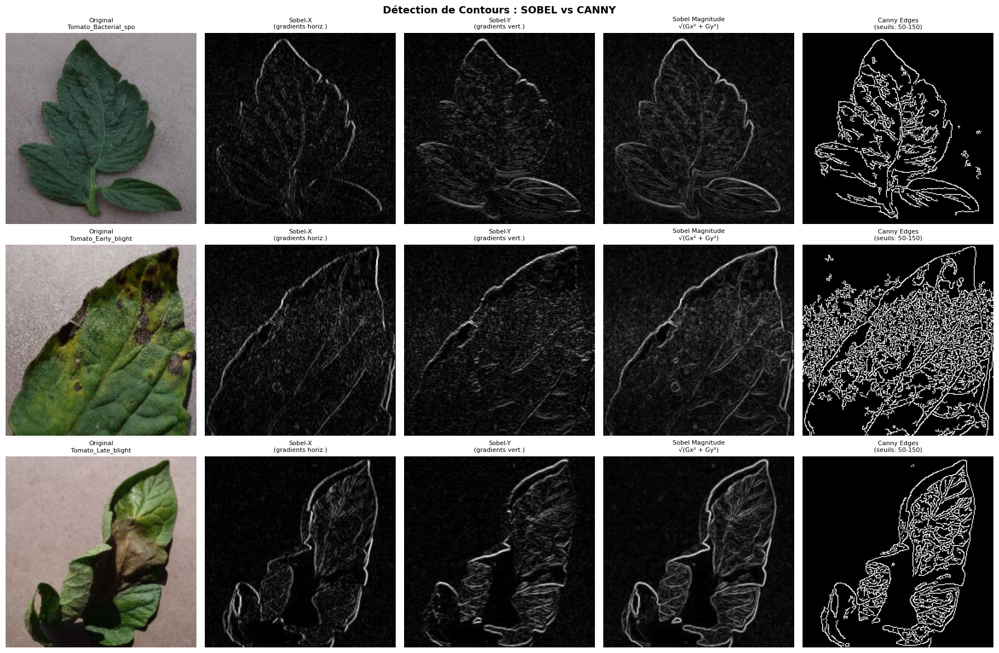


RÉSULTATS :
  • Sobel : bon pour détecter les gradients, mais produit des contours "épais"
  • Canny : produit des contours fins et connectés, meilleur pour segmentation

CHOIX : Canny est retenu pour la détection d'edges (plus robuste)


--------------------------------------------------------------------------------
7.2 - Seuillage Simple et Adaptatif
--------------------------------------------------------------------------------


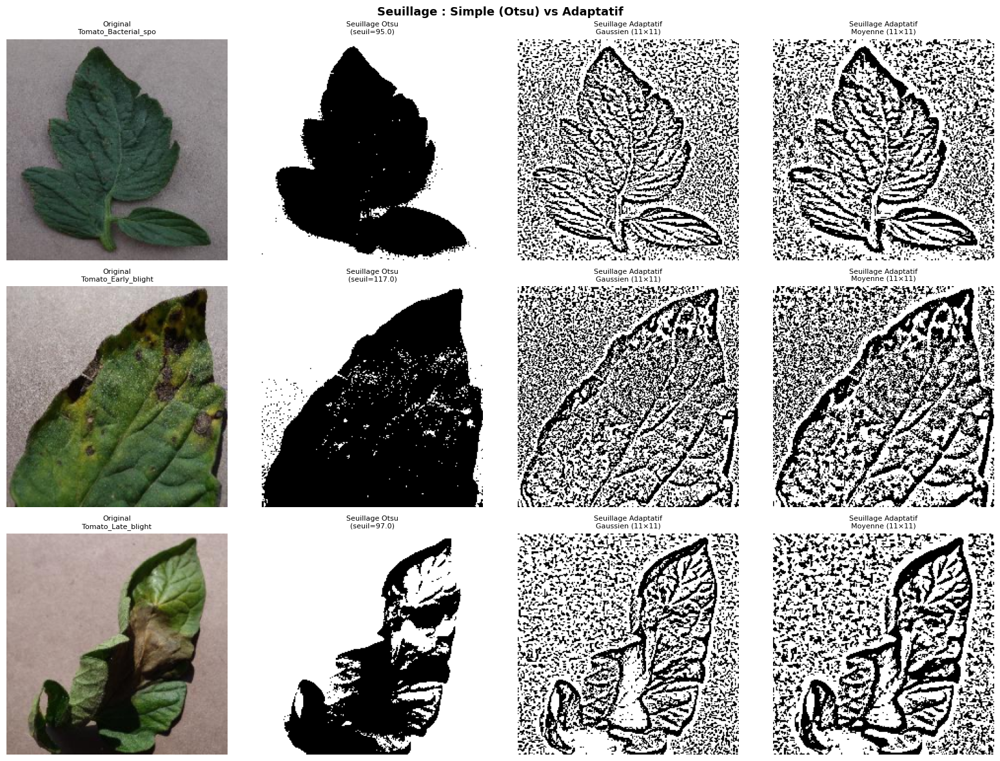


RÉSULTATS :
  • Otsu simple : bon quand éclairage homogène
  • Adaptatif Gaussien : MEILLEUR pour images avec variations d'éclairage
  • Adaptatif Moyenne : légèrement moins robuste

CHOIX : Seuillage adaptatif Gaussien (robuste + résultat net)


--------------------------------------------------------------------------------
7.3 - Segmentation Couleur HSV pour les Feuilles Vertes
--------------------------------------------------------------------------------


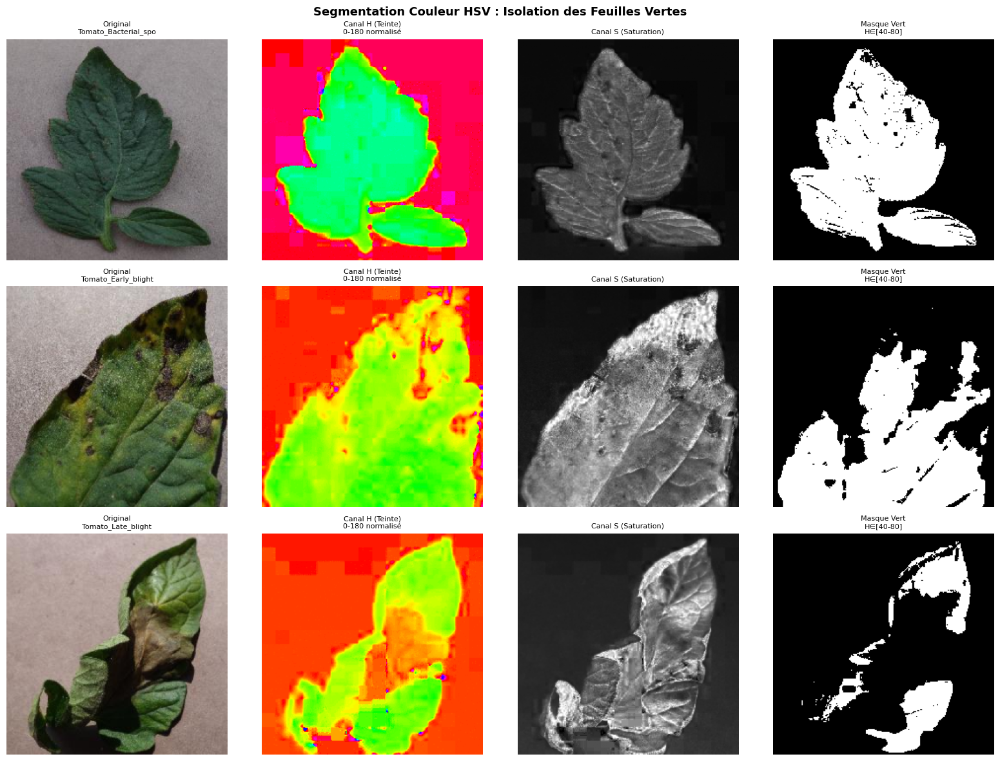


RÉSULTATS :
  • Le masque isole bien les régions vertes
  • Anomalies (taches brunes/jaunes) exclus du masque
  • Efficace pour feuilles saines et faiblement altérées

LIMITATION :
  • Feuilles très malades (peu de vert restant) := mal détectées

UTILITÉ :
  • Pré-traitement pour nettoyer le fond
  • Combiné avec autres méthodes pour robustesse


--------------------------------------------------------------------------------
7.4 - Segmentation par Clustering KMeans
--------------------------------------------------------------------------------


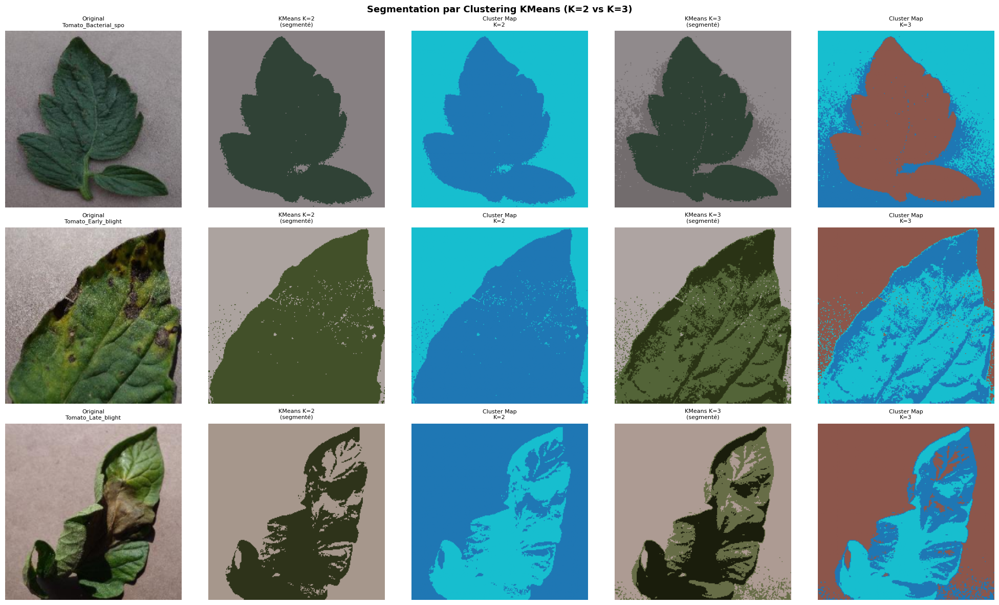


RÉSULTATS :
  • K=2 : fond vs feuille (séparation brute)
  • K=3 : fond, feuille saine, zones malades (plus détaillé)

AVANTAGES :
  • Automatique : pas de paramètres "magiques"
  • Évite les feuilles : détecte régions similaires
  • Permet isolation de lésions

LIMITATIONS :
  • KMeans aléatoire (n_init=10 pour stabilité)
  • Hyper-param K critiquement important

UTILITÉ :
  • Pré-traitement robuste
  • Détection anomalies sans seuil manuel


--------------------------------------------------------------------------------
7.5 - Fonction Segmentation Unifiée
--------------------------------------------------------------------------------

Démonstration de la fonction segmentation unifiée...


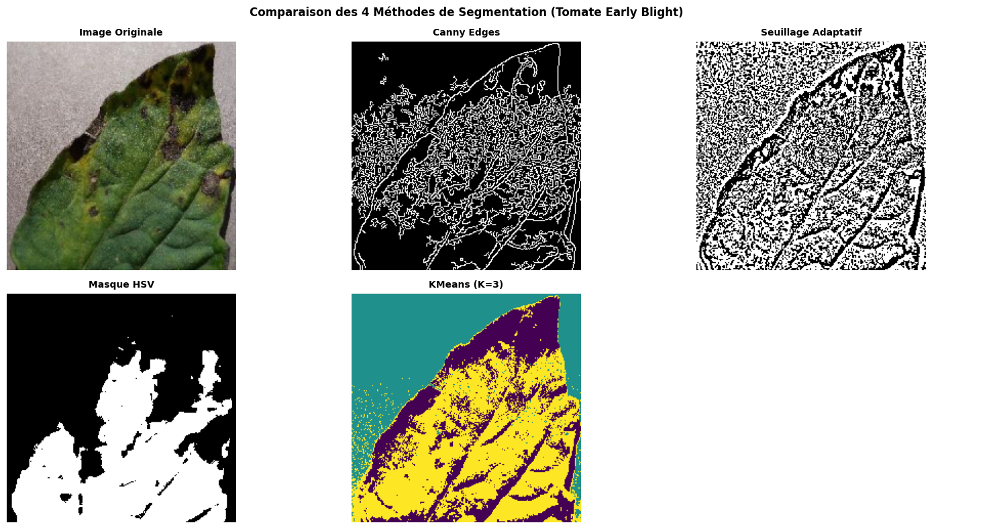


✓ Fonction segment_image() prête à être utilisée dans l'extraction de features

CHOIX RECOMMANDÉ : 'adaptive_threshold' ou 'hsv_mask'
  • Rapide, efficace, robuste
  • Produit masques binaires clairs
  • Bon pré-traitement pour features


--------------------------------------------------------------------------------
7.6 - Morphologie Mathématique : Fermeture et Ouverture
--------------------------------------------------------------------------------


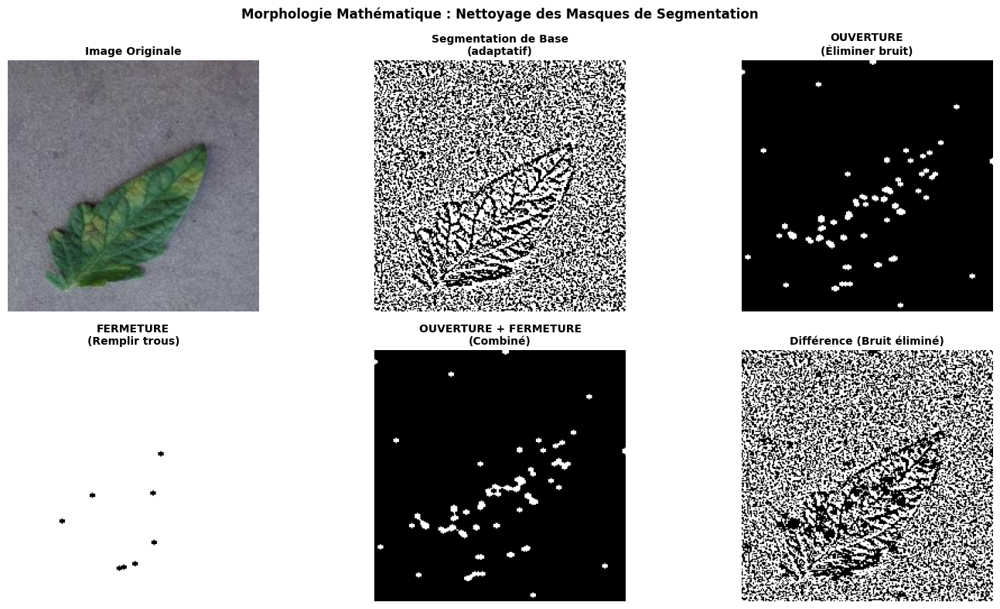


RÉSULTATS :
  • Ouverture : nettoie les petits bruits blancs
  • Fermeture : remplit les trous noirs dans le fond
  • Combinaison : meilleur compromis

UTILITÉ :
  • Post-traitement des masques de segmentation
  • Améliore la qualité pour l'extraction de features


✓ SECTION 7 - SEGMENTATION TERMINÉE

RÉSUMÉ :
  ✓ Détection de contours (Sobel, Canny)
  ✓ Seuillage (simple, adaptatif)
  ✓ Segmentation couleur HSV
  ✓ Clustering KMeans
  ✓ Morphologie mathématique
  ✓ Fonction segment_image() unifiée

PROCHAINE ÉTAPE : Extraction de Features (Couleur, GLCM, Forme, etc.)



In [ ]:
print("\n" + "="*80)
print("SECTION 7 - SEGMENTATION ET EXTRACTION DE CONTOURS")
print("="*80)

# ============================================================================
# 7.0 - DESCRIPTION GÉNÉRALE
# ============================================================================
"""
OBJECTIF : Segmenter la feuille du fond et détecter les zones de lésions.

JUSTIFICATION :
  • Éliminer le bruit du fond (feuillage, sol, lumière)
  • Isoler la région d'intérêt (ROI) = feuille
  • Détecter les changements de texture/couleur = lésions
  • Préparer l'extraction de features sur la feuille uniquement

APPROCHES TESTÉES :
  1. Détection de contours : Sobel, Canny Edge Detection
  2. Seuillage simple et adaptatif
  3. Segmentation couleur HSV (pour isoler la teinte verte)
  4. Segmentation par clustering (KMeans)

"""

# ============================================================================
# 7.1 - DÉTECTION DE CONTOURS : SOBEL ET CANNY
# ============================================================================
print("\n" + "-"*80)
print("7.1 - Détection de contours : SOBEL et CANNY")
print("-"*80)

"""
SOBEL :
  • Opérateur de gradient qui calcule les dérivées (Gx, Gy) de l'image (Le gradient est MAXIMAL aux contours)
  • Détecte les changements d'intensité = contours
  • Rapide, bon pour les transitions nettes
  • Sensible au bruit

CANNY EDGE DETECTION :
  • Algorithme plus sophistiqué (5 étapes : Gaussien, Gradients, Non-Maximum Suppression, 
    Double Seuillage, Hystérésis)
  • Plus robuste au bruit et produit des contours fins et précis
  • Standard industriel pour la détection d'edges
"""

# Charger une image d'exemple de chaque classe
sample_images = {}
for cls in sorted(df_tomato['class'].unique())[:6]:  # 6 classes différentes
    path = df_tomato[df_tomato['class'] == cls].iloc[0]['path']
    img = preprocess_image(path)
    sample_images[cls] = img

# Afficher Sobel vs Canny sur 3 classes
fig, axes = plt.subplots(3, 5, figsize=(18, 12))
classes_to_show = list(sample_images.keys())[:3]

for row, cls in enumerate(classes_to_show):
    img_rgb = sample_images[cls]['rgb']
    img_gray = sample_images[cls]['gray']
    
    # 1. Image originale
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Original\n{cls[:20]}", fontsize=8)
    axes[row, 0].axis('off')
    
    # 2. SOBEL-X (gradient horizontal)
    """Sobel-X= 
                    ∂x
                    ∂I
​"""
    sobel_x = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3) #1 : dérivée par rapport à x, 0 : pas de dérivée par rapport à y
    sobel_x = np.abs(sobel_x)#prendre la valeur absolue pour éviter les valeurs négatives (gradient peut être positif ou négatif)
    sobel_x_norm = cv2.normalize(sobel_x, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)#normaliser les valeurs pour les afficher correctement (0-255) ca veut dire que la valeur minimale de sobel_x devient 0 et la valeur maximale devient 255
    axes[row, 1].imshow(sobel_x_norm, cmap='gray')
    axes[row, 1].set_title("Sobel-X\n(gradients horiz.)", fontsize=8)
    axes[row, 1].axis('off')
    
    # 3. SOBEL-Y (gradient vertical)
    sobel_y = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_y = np.abs(sobel_y)
    sobel_y_norm = cv2.normalize(sobel_y, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    axes[row, 2].imshow(sobel_y_norm, cmap='gray')
    axes[row, 2].set_title("Sobel-Y\n(gradients vert.)", fontsize=8)
    axes[row, 2].axis('off')
    
    # 4. SOBEL magnitude (2D)
    sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)
    sobel_mag_norm = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    axes[row, 3].imshow(sobel_mag_norm, cmap='gray')
    axes[row, 3].set_title("Sobel Magnitude\n√(Gx² + Gy²)", fontsize=8)
    axes[row, 3].axis('off')
    
    # 5. CANNY Edge Detection
    # Étapes : Gaussien(5×5)(pour Réduire le bruit pour éviter de détecter des faux contours) → Gradient → NMS(Non-Maximum Suppression: Amincir les contours (les rendre d'1 pixel d'épaisseur)) → Double seuillage(Divise les pixels en 3 catégories avec 2 seuils) → Hystérésis(Valider les contours faibles = décider si on les garde ou pas)
    # Paramètres : threshold_low=50, threshold_high=150
    canny_edges = cv2.Canny(img_gray, 50, 150)
    axes[row, 4].imshow(canny_edges, cmap='gray')
    axes[row, 4].set_title("Canny Edges\n(seuils: 50-150)", fontsize=8)
    axes[row, 4].axis('off')

plt.suptitle("Détection de Contours : SOBEL vs CANNY", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('segmentation_edges.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
RÉSULTATS :
  • Sobel : bon pour détecter les gradients, mais produit des contours "épais"
  • Canny : produit des contours fins et connectés, meilleur pour segmentation
  
CHOIX : Canny est retenu pour la détection d'edges (plus robuste)
""")

# ============================================================================
# 7.2 - SEUILLAGE SIMPLE ET ADAPTATIF
# ============================================================================
print("\n" + "-"*80)
print("7.2 - Seuillage Simple et Adaptatif")
print("-"*80)

"""
SEUILLAGE :
  • Convertir image grise en binaire (noir/blanc) en fixant un seuil
  • Pixels > seuil → blanc, sinon noir
  • Utile pour segmenter feuille (verte) du fond (autre couleur)

TYPES :
  1. Seuillage global : seuil fixe pour toute l'image
  2. Seuillage adaptatif (ADAPTIVE_THRESH_GAUSSIAN_C) : calcule seuil local (moyenne 11×11)
     → Robuste aux variations d'éclairage (Calculer un seuil DIFFÉRENT pour chaque pixel en regardant ses voisins)
"""

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, cls in enumerate(classes_to_show):
    img_rgb = sample_images[cls]['rgb']
    img_gray = sample_images[cls]['gray']
    
    # 1. Image originale
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Original\n{cls[:20]}", fontsize=8)
    axes[row, 0].axis('off')
    
    # 2. Seuillage global simple (Otsu)
    # Otsu = calcule automatiquement le meilleur seuil
    # Concept: Un seul seuil fixe pour toute l'image
    """Si pixel > seuil  →  255 (blanc)
    Sinon             →    0 (noir)"""
    """La fonction cv2.threshold() supporte plusieurs méthodes différentes. Elle a besoin de savoir laquelle utiliser!
    *THRESH_BINARY : seuil binaire classique
    *THRESH_OTSU : calcule automatiquement le meilleur seuil en utilisant la méthode d'Otsu
    OTSU : trouve le seuil qui minimise la variance intra-classe (sépare au mieux les pixels en 2 classes : feuille vs fond)"""
    _, thresh_otsu = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU) # 0 : seuil automatique, 255 : valeur max, cv2.THRESH_BINARY : seuillage binaire, cv2.THRESH_OTSU : seuillage Otsu
    axes[row, 1].imshow(thresh_otsu, cmap='gray')
    seuil_otsu = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0]
    axes[row, 1].set_title(f"Seuillage Otsu\n(seuil={seuil_otsu})", fontsize=8)
    axes[row, 1].axis('off')
    
    # 3. Seuillage adaptatif Gaussien
    # Concept: Un seuil différent pour chaque pixel, calculé à partir de la moyenne pondérée de ses voisins (11×11)
    thresh_adaptive = cv2.adaptiveThreshold(
        img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, blockSize=11, C=2 #C : valeur soustraite du seuil calculé pour affiner la segmentation
        #ADAPTIVE_THRESH_GAUSSIAN_C : méthode de calcul du seuil adaptatif (moyenne pondérée gaussienne des voisins)
        #THRESH_BINARY : type de seuillage (binaire classique)
    )
    axes[row, 2].imshow(thresh_adaptive, cmap='gray')
    axes[row, 2].set_title("Seuillage Adaptatif\nGaussien (11×11)", fontsize=8)
    axes[row, 2].axis('off')
    
    # 4. Seuillage adaptatif Moyenne
    thresh_adaptive_mean = cv2.adaptiveThreshold(
        img_gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY, blockSize=11, C=2
    ) #ADAPTIVE_THRESH_MEAN_C : méthode de calcul du seuil adaptatif (moyenne des voisins) 
    #Comparaison : Gaussien (pondération plus forte des pixels proches) vs Moyenne (pondération égale de tous les voisins)
    axes[row, 3].imshow(thresh_adaptive_mean, cmap='gray')
    axes[row, 3].set_title("Seuillage Adaptatif\nMoyenne (11×11)", fontsize=8)
    axes[row, 3].axis('off')

plt.suptitle("Seuillage : Simple (Otsu) vs Adaptatif", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('segmentation_threshold.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
RÉSULTATS :
  • Otsu simple : bon quand éclairage homogène
  • Adaptatif Gaussien : MEILLEUR pour images avec variations d'éclairage
  • Adaptatif Moyenne : légèrement moins robuste
  
CHOIX : Seuillage adaptatif Gaussien (robuste + résultat net)
""")

# ============================================================================
# 7.3 - SEGMENTATION COULEUR HSV
# ============================================================================
print("\n" + "-"*80)
print("7.3 - Segmentation Couleur HSV pour les Feuilles Vertes")
print("-"*80)

"""
CONCEPT :
  • HSV = Hue (Teinte 0-180), Saturation (0-255), Value (0-255)
  • Les feuilles vertes ont une teinte H spécifique : environ 40-80
  • Les lésions/fonds ont des teintes différentes
  
AVANTAGE :
  • Robuste aux variations de luminosité (V peut varier)
  • Séparation claire teinte verte des anomalies
"""

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# Gammes de couleur en HSV
# Vert feuille : H ≈ 40-80 (normalisé en OpenCV : H = [0-180])
lower_green = np.array([40, 40, 40])      # H_min, S_min, V_min pour vert
upper_green = np.array([80, 255, 255])    # H_max, S_max, V_max pour vert

for row, cls in enumerate(classes_to_show):
    img_rgb = sample_images[cls]['rgb']
    img_hsv = sample_images[cls]['hsv']
    
    # 1. Image originale
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Original\n{cls[:20]}", fontsize=8)
    axes[row, 0].axis('off')
    
    # 2. Afficher canal H (Hue)
    axes[row, 1].imshow(img_hsv[:,:,0], cmap='hsv')
    axes[row, 1].set_title("Canal H (Teinte)\n0-180 normalisé", fontsize=8)
    axes[row, 1].axis('off')
    
    # 3. Afficher canal S (Saturation)
    axes[row, 2].imshow(img_hsv[:,:,1], cmap='gray')
    axes[row, 2].set_title("Canal S (Saturation)", fontsize=8)
    axes[row, 2].axis('off')
    
    # 4. Masque pour feuilles vertes (inRange)
    mask_green = cv2.inRange(img_hsv, lower_green, upper_green) #inRange : crée un masque binaire où les pixels dans la gamme spécifiée sont blancs (255) et les autres sont noirs (0)
    axes[row, 3].imshow(mask_green, cmap='gray')
    axes[row, 3].set_title(f"Masque Vert\nH∈[40-80]", fontsize=8)
    axes[row, 3].axis('off')

plt.suptitle("Segmentation Couleur HSV : Isolation des Feuilles Vertes", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('segmentation_hsv.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
RÉSULTATS :
  • Le masque isole bien les régions vertes
  • Anomalies (taches brunes/jaunes) exclus du masque
  • Efficace pour feuilles saines et faiblement altérées
  
LIMITATION :
  • Feuilles très malades (peu de vert restant) := mal détectées
  
UTILITÉ :
  • Pré-traitement pour nettoyer le fond
  • Combiné avec autres méthodes pour robustesse
""")

# ============================================================================
# 7.4 - SEGMENTATION PAR CLUSTERING (KMeans)
# ============================================================================
print("\n" + "-"*80)
print("7.4 - Segmentation par Clustering KMeans")
print("-"*80)

"""
CONCEPT :
  • Grouper les pixels en K clusters basés sur leur couleur/intensité
  • Chaque cluster = région avec couleur similaire
  • KMeans : algorithme itératif de partitionnement

PROCESSUS :
  1. Vectoriser image 224×224×3 → array (50176, 3)
  2. Appliquer KMeans(k=3) : 3 clusters (ex: fond, feuille saine, lésion)
  3. Chaque pixel assigné à son cluster le plus proche
  4. Afficher cluster maps colorés
"""

fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for row, cls in enumerate(classes_to_show):
    img_rgb = sample_images[cls]['rgb']
    
    # 1. Image originale
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Original\n{cls[:20]}", fontsize=8)
    axes[row, 0].axis('off')
    
    # Vectoriser l'image : (224, 224, 3) → (50176, 3)
    pixels = img_rgb.reshape((-1, 3)).astype(np.float32)
    
    # Appliquer KMeans avec K=3 clusters
    #col_offset : pour afficher les résultats dans les bonnes colonnes (1 et 3)
    #Diff entre Kmeans et cluster map : KMeans donne les centres de clusters et les labels d'appartenance, cluster map affiche les labels sous forme d'image
    for k_val, col_offset in [(2, 1), (3, 3)]:  # K=2 et K=3
        kmeans = KMeans(n_clusters=k_val, random_state=42, n_init=10)
        kmeans.fit(pixels)
        labels = kmeans.labels_
        centers = kmeans.cluster_centers_.astype(np.uint8)
        
        # Créer image segmentée
        segmented_img = centers[labels]
        segmented_img = segmented_img.reshape(img_rgb.shape)
        
        # Afficher image segmentée
        axes[row, col_offset].imshow(segmented_img)
        axes[row, col_offset].set_title(f"KMeans K={k_val}\n(segmenté)", fontsize=8)
        axes[row, col_offset].axis('off')
        
        # Afficher map d'étiquettes (chaque couleur = un cluster)
        label_map = labels.reshape((224, 224))
        cmap_discrete = plt.cm.get_cmap('tab10', k_val)
        axes[row, col_offset + 1].imshow(label_map, cmap=cmap_discrete)
        axes[row, col_offset + 1].set_title(f"Cluster Map\nK={k_val}", fontsize=8)
        axes[row, col_offset + 1].axis('off')

plt.suptitle("Segmentation par Clustering KMeans (K=2 vs K=3)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('segmentation_kmeans.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
RÉSULTATS :
  • K=2 : fond vs feuille (séparation brute)
  • K=3 : fond, feuille saine, zones malades (plus détaillé)
  
AVANTAGES :
  • Automatique : pas de paramètres "magiques"
  • Évite les feuilles : détecte régions similaires
  • Permet isolation de lésions
  
LIMITATIONS :
  • KMeans aléatoire (n_init=10 pour stabilité)
  • Hyper-param K critiquement important
  
UTILITÉ :
  • Pré-traitement robuste
  • Détection anomalies sans seuil manuel
""")

# ============================================================================
# 7.5 - FONCTION SEGMENTATION UNIFIÉE
# ============================================================================
print("\n" + "-"*80)
print("7.5 - Fonction Segmentation Unifiée")
print("-"*80)

def segment_image(img_rgb, method='adaptive_threshold'):
    """
    Segmente une image RGB en utilisant la méthode spécifiée.
    
    Parameters:
    -----------
    img_rgb : np.ndarray de shape (224, 224, 3)
        Image RGB prétraitée (normalisée ou non)
    method : str
        'canny' : Canny edge detection
        'adaptive_threshold' : Seuillage adaptatif Gaussien
        'hsv_mask' : Masque HSV pour feuilles vertes
        'kmeans' : Clustering KMeans (K=3)
    
    Returns:
    --------
    segmented : np.ndarray
        Résultat de segmentation (format dépend de la méthode)
    """
    
    # Convertir en entiers 0-255 si normalisé en [0,1]
    if img_rgb.dtype == np.float32 or img_rgb.dtype == np.float64:
        img_rgb = (img_rgb * 255).astype(np.uint8)
    
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    
    if method == 'canny':
        # Canny Edge Detection
        return cv2.Canny(img_gray, 50, 150)
    
    elif method == 'adaptive_threshold':
        # Seuillage adaptatif Gaussien
        return cv2.adaptiveThreshold(
            img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, blockSize=11, C=2
        )
    
    elif method == 'hsv_mask':
        # Masque HSV pour feuilles vertes
        img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
        lower_green = np.array([40, 40, 40])
        upper_green = np.array([80, 255, 255])
        return cv2.inRange(img_hsv, lower_green, upper_green)
    
    elif method == 'kmeans':
        # Clustering KMeans
        pixels = img_rgb.reshape((-1, 3)).astype(np.float32)
        kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
        kmeans.fit(pixels)
        labels = kmeans.labels_.reshape((224, 224))
        return labels.astype(np.uint8) * 85  # Normaliser pour affichage [0, 255]
    
    else:
        raise ValueError(f"Méthode inconnue : {method}")

# Démonstration sur toutes les 4 méthodes
print("\nDémonstration de la fonction segmentation unifiée...")
img_test = preprocess_image(df_tomato[df_tomato['class'] == 'Tomato_Early_blight'].iloc[0]['path'])
img_test_rgb = img_test['rgb']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Originale
axes[0, 0].imshow(img_test_rgb)
axes[0, 0].set_title("Image Originale", fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

# 4 méthodes
methods = ['canny', 'adaptive_threshold', 'hsv_mask', 'kmeans']
titles = ['Canny Edges', 'Seuillage Adaptatif', 'Masque HSV', 'KMeans (K=3)']
positions = [(0, 1), (0, 2), (1, 0), (1, 1)]

for method, title, (row, col) in zip(methods, titles, positions):
    result = segment_image(img_test_rgb, method=method)
    cmap = None if method == 'kmeans' else 'gray'
    axes[row, col].imshow(result, cmap=cmap)
    axes[row, col].set_title(title, fontsize=10, fontweight='bold')
    axes[row, col].axis('off')

# Cacher l'axe inutilisé
axes[1, 2].axis('off')

plt.suptitle("Comparaison des 4 Méthodes de Segmentation (Tomate Early Blight)", 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('segmentation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
✓ Fonction segment_image() prête à être utilisée dans l'extraction de features
  
CHOIX RECOMMANDÉ : 'adaptive_threshold' ou 'hsv_mask'
  • Rapide, efficace, robuste
  • Produit masques binaires clairs
  • Bon pré-traitement pour features
""")

# ============================================================================
# 7.6 - MORPHOLOGIE MATHÉMATIQUE (Post-processing)
# ============================================================================
print("\n" + "-"*80)
print("7.6 - Morphologie Mathématique : Fermeture et Ouverture")
print("-"*80)
# **Concept :** Opérations de morphologie mathématique pour nettoyer les masques de segmentation
# **Description :** Érosion, dilatation, ouverture, fermeture
"""
MORPHOLOGIE MATHÉMATIQUE :
  • Érosion : réduit régions blanches (élargit contours)
  • Dilatation : élargit régions blanches (réduit contours)
  • Ouverture (Erosion + Dilatation) : éliminer petites objets (bruit)
  • Fermeture (Dilatation + Erosion) : remplir petits trous

"""

# Créer un kernel (élément structurant)
# Role : définit la forme et la taille de l'opération morphologique
# Ici, un kernel elliptique de 5x5 pixels pour un effet plus doux
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
img_test = preprocess_image(df_tomato[df_tomato['class'] == 'Tomato_Leaf_Mold'].iloc[0]['path'])
img_test_rgb = img_test['rgb']

# Segmentation de base
# Principe : appliquer la fonction de segmentation unifiée pour obtenir un masque de base à nettoyer
seg_base = segment_image(img_test_rgb, method='adaptive_threshold')

# Morphologie
# Ouverture : élimine les petits bruits blancs (petits objets indésirables)
# Fermeture : remplit les trous noirs dans le fond (petits objets manquants)
seg_opening = cv2.morphologyEx(seg_base, cv2.MORPH_OPEN, kernel)  # Éliminer bruit
seg_closing = cv2.morphologyEx(seg_base, cv2.MORPH_CLOSE, kernel)  # Remplir trous

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Row 1
axes[0, 0].imshow(img_test_rgb)
axes[0, 0].set_title("Image Originale", fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(seg_base, cmap='gray')
axes[0, 1].set_title("Segmentation de Base\n(adaptatif)", fontsize=10, fontweight='bold')
axes[0, 1].axis('off')

axes[0, 2].imshow(seg_opening, cmap='gray')
axes[0, 2].set_title("OUVERTURE\n(Éliminer bruit)", fontsize=10, fontweight='bold')
axes[0, 2].axis('off')

# Row 2
axes[1, 0].imshow(seg_closing, cmap='gray')
axes[1, 0].set_title("FERMETURE\n(Remplir trous)", fontsize=10, fontweight='bold')
axes[1, 0].axis('off')

seg_opening_closing = cv2.morphologyEx(cv2.morphologyEx(seg_base, cv2.MORPH_OPEN, kernel),
                                       cv2.MORPH_CLOSE, kernel)
axes[1, 1].imshow(seg_opening_closing, cmap='gray')
axes[1, 1].set_title("OUVERTURE + FERMETURE\n(Combiné)", fontsize=10, fontweight='bold')
axes[1, 1].axis('off')

axes[1, 2].imshow(cv2.absdiff(seg_base, seg_opening_closing), cmap='gray')
axes[1, 2].set_title("Différence (Bruit éliminé)", fontsize=10, fontweight='bold')
axes[1, 2].axis('off')

plt.suptitle("Morphologie Mathématique : Nettoyage des Masques de Segmentation", 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('segmentation_morphology.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
RÉSULTATS :
  • Ouverture : nettoie les petits bruits blancs
  • Fermeture : remplit les trous noirs dans le fond
  • Combinaison : meilleur compromis
  
UTILITÉ :
  • Post-traitement des masques de segmentation
  • Améliore la qualité pour l'extraction de features
""")

print("\n" + "="*80)
print("✓ SECTION 7 - SEGMENTATION TERMINÉE")
print("="*80)
print("""
RÉSUMÉ :
  ✓ Détection de contours (Sobel, Canny)
  ✓ Seuillage (simple, adaptatif)
  ✓ Segmentation couleur HSV
  ✓ Clustering KMeans
  ✓ Morphologie mathématique
  ✓ Fonction segment_image() unifiée

PROCHAINE ÉTAPE : Extraction de Features (Couleur, GLCM, Forme, etc.)
""")